In [2]:
import yfinance as yf
import pandas as pd
from ta.trend import SMAIndicator, EMAIndicator, MACD
from ta.momentum import RSIIndicator
from ta.volatility import BollingerBands

# ૧. સેલ સેટિંગ્સ અને પેરામીટર્સ
ticker = "PAYTM.NS"
csv_filename = "paytm_market_data.csv"

print(f"Downloading {ticker} data from Yahoo Finance...")

# ૨. auto_adjust=False સાથે નવો ડેટા ડાઉનલોડ (બોનસ એડજસ્ટમેન્ટ માટે)
df = yf.download(
    ticker,
    start="2022-01-01",
    end="2026-10-18",  # આજની તારીખ સુધીનો ડેટા
    auto_adjust=False,
    progress=False
)

# MultiIndex કોલમ્સ સાફ કરો
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.dropna()

# ૩. બધા ટેકનિકલ ઇન્ડિકેટર્સની ગણતરી ('Adj Close' નો ઉપયોગ કરીને)
df["SMA_10"] = SMAIndicator(close=df["Adj Close"], window=10).sma_indicator()
df["SMA_20"] = SMAIndicator(close=df["Adj Close"], window=20).sma_indicator()
df["EMA_12"] = EMAIndicator(close=df["Adj Close"], window=12).ema_indicator()
df["EMA_26"] = EMAIndicator(close=df["Adj Close"], window=26).ema_indicator()
df["RSI_14"] = RSIIndicator(close=df["Adj Close"], window=14).rsi()

macd = MACD(close=df["Adj Close"], window_slow=26, window_fast=12, window_sign=9)
df["MACD"] = macd.macd()
df["MACD_signal"] = macd.macd_signal()

bb = BollingerBands(close=df["Adj Close"], window=20, window_dev=2)
df["BB_upper"] = bb.bollinger_hband()
df["BB_lower"] = bb.bollinger_lband()

df["Return_1d"] = df["Adj Close"].pct_change()
df["Volatility_20"] = df["Return_1d"].rolling(window=20).std()

# Target (આવતીકાલનો ભાવ) ઉમેરો
df["Target"] = df["Adj Close"].shift(-1)

# બાકી રહેલી ખાલી રો (NaN) કાઢી નાખો
df = df.dropna()

# ૪. ડેટાને CSV ફાઇલમાં એક્સપોર્ટ કરો
df.to_csv(csv_filename)

print("=" * 50)
print(f"🎉 ડેટા સફળતાપૂર્વક '{csv_filename}' ફાઇલમાં સેવ થઈ ગયો છે!")
print(f"📊 કુલ રેકોર્ડ્સ (Rows): {df.shape[0]} | કોલમ્સ (Columns): {df.shape[1]}")
print(f"💰 છેલ્લો ઉપલબ્ધ સાચો ભાવ (Adj Close): ₹{df['Adj Close'].iloc[-1]:.2f}")
print("=" * 50)


🎉 ડેટા સફળતાપૂર્વક 'paytm_market_data.csv' ફાઇલમાં સેવ થઈ ગયો છે!
📊 કુલ રેકોર્ડ્સ (Rows): 1150 | કોલમ્સ (Columns): 18
💰 છેલ્લો ઉપલબ્ધ સાચો ભાવ (Adj Close): ₹1712.30


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("paytm_market_data.csv")

df.head()


,Date,Adj Close,Close,High,Low,Open,Volume,SMA_10,SMA_20,EMA_12,EMA_26,RSI_14,MACD,MACD_signal,BB_upper,BB_lower,Return_1d,Volatility_20,Target
0,2022-02-18,833.400024,833.400024,848.000000,831.000000,844.799988,1325802,894.154999,913.409995,892.915901,963.377191,22.241884,-70.461290,-70.716760,995.125594,831.694395,-0.019472,0.023571,807.700012
1,2022-02-21,807.700012,807.700012,834.000000,805.000000,832.500000,1975577,879.170001,905.779996,879.805764,951.845548,20.114662,-72.039784,-70.981365,996.553106,815.006886,-0.030838,0.023330,815.900024
2,2022-02-22,815.900024,815.900024,834.650024,785.000000,800.000000,3701578,866.965002,900.702496,869.974112,941.775509,22.656404,-71.801397,-71.145372,999.318304,802.086689,0.010152,0.022027,821.950012
3,2022-02-23,821.950012,821.950012,837.049988,815.250000,823.000000,1575013,855.010004,896.059998,862.585789,932.899546,24.563492,-70.313758,-70.979049,1000.172961,791.947034,0.007415,0.022214,777.750000
4,2022-02-24,777.750000,777.750000,802.849976,771.150024,790.000000,1917591,838.950006,890.262497,849.534129,921.406987,20.572460,-71.872859,-71.157811,1006.466638,774.058356,-0.053775,0.024468,789.349976


In [4]:

print(df.columns)

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# Close price use karna hai, Adj Close nahi
df = df[["Date", "Close"]].copy()

df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df = df.dropna()

df.head()


Index(['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'SMA_10',
       'SMA_20', 'EMA_12', 'EMA_26', 'RSI_14', 'MACD', 'MACD_signal',
       'BB_upper', 'BB_lower', 'Return_1d', 'Volatility_20', 'Target'],
      dtype='object')


,Date,Close
0,2022-02-18,833.400024
1,2022-02-21,807.700012
2,2022-02-22,815.900024
3,2022-02-23,821.950012
4,2022-02-24,777.750000


In [5]:

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Next trading day's Close
df["Target"] = df["Close"].shift(-1)
df = df.dropna().reset_index(drop=True)

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

split = int(len(df) * 0.80)

# Chronological 80:20 split
X_values = df[["Close"]].values
y_values = df[["Target"]].values

scaler_X.fit(X_values[:split])
scaler_y.fit(y_values[:split])

X_scaled = scaler_X.transform(X_values)
y_scaled = scaler_y.transform(y_values)

WINDOW_SIZE = 60

X, y = [], []

for i in range(WINDOW_SIZE - 1, len(df)):
    X.append(X_scaled[i - WINDOW_SIZE + 1:i + 1])
    y.append(y_scaled[i])

X = np.array(X)
y = np.array(y)

# Split sequences by time
split_seq = split - WINDOW_SIZE + 1

X_train, X_test = X[:split_seq], X[split_seq:]
y_train, y_test = y[:split_seq], y[split_seq:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (860, 60, 1)
X_test: (230, 60, 1)


In [6]:

model = Sequential([
    LSTM(64, return_sequences=True,
         input_shape=(WINDOW_SIZE, 1)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)


C:\Users\admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - loss: 0.0417 - val_loss: 0.0744
Epoch 2/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - loss: 0.0085 - val_loss: 0.0177
Epoch 3/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0072 - val_loss: 0.0047
Epoch 4/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0060 - val_loss: 0.0026
Epoch 5/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - loss: 0.0065 - val_loss: 0.0025
Epoch 6/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0060 - val_loss: 0.0026
Epoch 7/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - loss: 0.0064 - val_loss: 0.0027
Epoch 8/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.0059 - val_loss: 0.0023
Epoch 9/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0069 - val_loss: 0.0022
Epoch 10/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0072 - val_loss: 0.0025
Epoch 11/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - loss: 0.0055 - val_loss: 0.0021
Epoch 12/30
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 0.0

MAE: 48.78
RMSE: 61.52


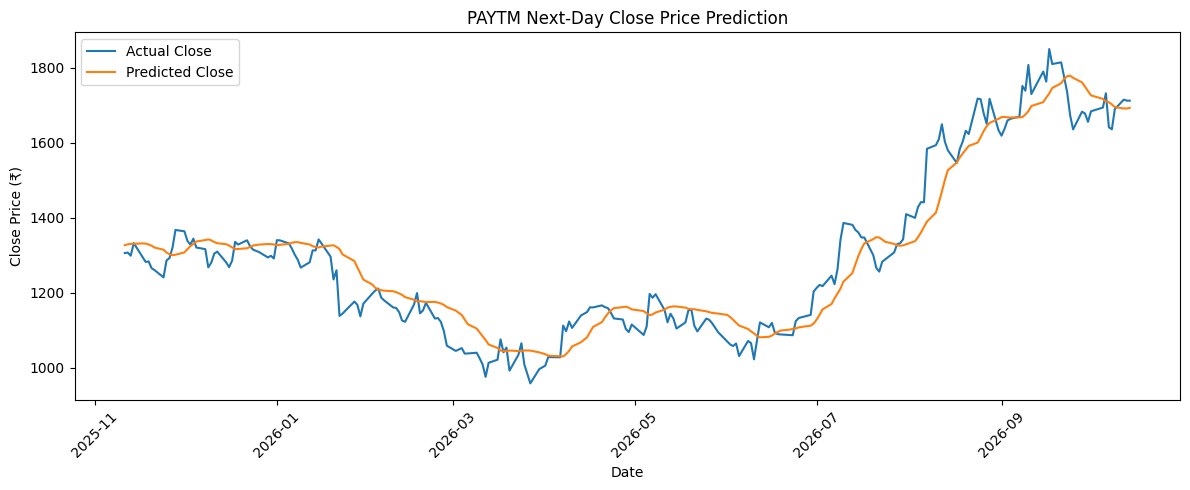

In [7]:

pred_scaled = model.predict(X_test, verbose=0)

y_actual = scaler_y.inverse_transform(y_test)
y_pred = scaler_y.inverse_transform(pred_scaled)

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

# Target dates are the next trading day
test_dates = df["Date"].iloc[
    WINDOW_SIZE + split_seq - 1:
].reset_index(drop=True)

plt.figure(figsize=(12, 5))
plt.plot(test_dates, y_actual.flatten(), label="Actual Close")
plt.plot(test_dates, y_pred.flatten(), label="Predicted Close")
plt.title("PAYTM Next-Day Close Price Prediction")
plt.xlabel("Date")
plt.ylabel("Close Price (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [8]:

# Show predicted Close prices
prediction_df = pd.DataFrame({
    "Date": test_dates,
    "Actual_Close": y_actual.flatten(),
    "Predicted_Close": y_pred.flatten()
})

print(prediction_df.tail(10).round(2).to_string(index=False))

# Predict next trading day's Close price
last_60_days = X_scaled[-WINDOW_SIZE:].reshape(
    1, WINDOW_SIZE, 1
)

next_scaled = model.predict(last_60_days, verbose=0)
next_price = scaler_y.inverse_transform(next_scaled)[0][0]

print(f"\nPredicted Next Trading Day Close Price: ₹{next_price:.2f}")


      Date  Actual_Close  Predicted_Close
2026-09-30        1656.0      1738.380005
2026-10-01        1684.0      1726.420044
2026-10-05        1694.0      1717.060059
2026-10-06        1732.0      1710.329956
2026-10-07        1641.5      1708.239990
2026-10-08        1636.0      1702.410034
2026-10-09        1690.0      1695.239990
2026-10-12        1715.0      1691.560059
2026-10-13        1712.4      1691.420044
2026-10-14        1712.3      1693.060059

Predicted Next Trading Day Close Price: ₹1693.06


MAE: 48.78
RMSE: 61.52
R2 Score: 0.9244
R2 Score (%): 92.44 %
Minimum Difference: ₹ 0.62
Maximum Difference: ₹ 193.77
Predictions within 10% error: 95.65 %


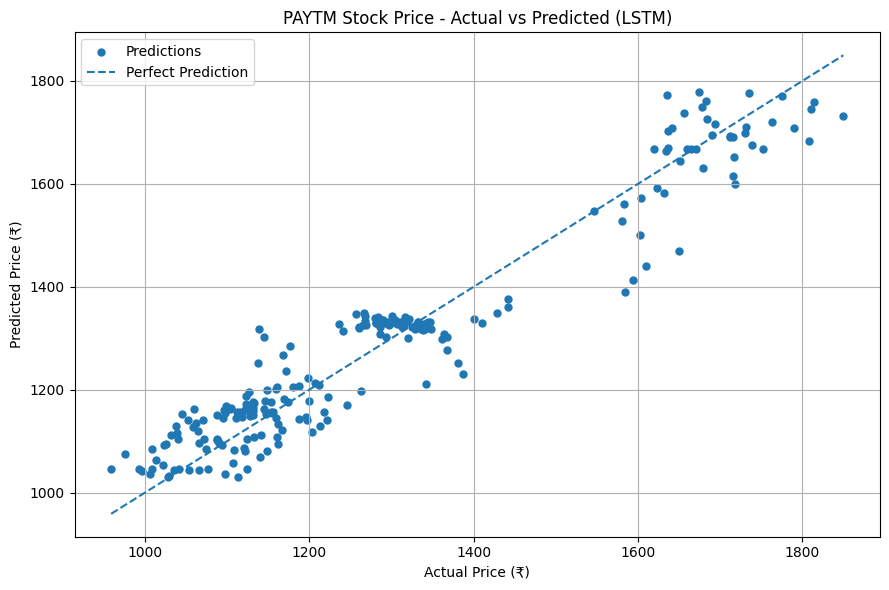

In [9]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

actual = y_actual.flatten()
predicted = y_pred.flatten()

# Metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
r2 = r2_score(actual, predicted)

diff = np.abs(actual - predicted)

percentage_error = (
    diff / np.maximum(np.abs(actual), 1e-8)
) * 100

within_10 = np.mean(percentage_error <= 10) * 100

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))
print("R2 Score (%):", round(r2 * 100, 2), "%")
print("Minimum Difference: ₹", round(diff.min(), 2))
print("Maximum Difference: ₹", round(diff.max(), 2))
print("Predictions within 10% error:", round(within_10, 2), "%")

# Actual vs Predicted scatter graph
plt.figure(figsize=(9, 6))

plt.scatter(actual, predicted, s=25, label="Predictions")

minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.title("PAYTM Stock Price - Actual vs Predicted (LSTM)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
